In [1]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
from scipy.stats import t
from matplotlib import pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
ROOT = Path.cwd().parent
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

In [3]:
def func_1(x, a, b):
    return a * x ** b

In [4]:
def fitting(X, Y):
    popt, pcov = curve_fit(func_1, X, Y)
    a, b = popt
    y_pred = func_1(X, a, b)
    r2 = r2_score(Y, y_pred)
    x_sim = np.linspace(min(X), max(X), 100)
    y_sim = func_1(x_sim, a, b)
    dof = len(X) - len(popt)

    return a, b, r2, x_sim, y_sim, popt, pcov, dof


def conf_band(x, popt, pcov, dof, alpha=0.05):
    """95% confidence band of the fitted power law A = a * E**b, propagated from the
    curve_fit parameter covariance via the delta method. This is the SAME construction
    as predict_interval() in notebook 6 (mining-area estimation), so the figure, its
    caption, and the uncertainty propagation stay mutually consistent."""
    a, b = popt
    f = a * x ** b
    df_da = x ** b
    df_db = a * x ** b * np.log(x)
    var = pcov[0, 0] * df_da ** 2 + 2 * pcov[0, 1] * df_da * df_db + pcov[1, 1] * df_db ** 2
    se = np.sqrt(var)
    tval = t.ppf(1 - alpha / 2, dof)
    return f - tval * se, f + tval * se

In [5]:
DF_1 = pd.read_csv(RESULTS / 'extraction-area-relationship.csv')

X = DF_1['E (Mt)'].values
Y = DF_1['A (ha)'].values
a, b, r2, x_sim, y_sim, popt, pcov, dof = fitting(X, Y)
y_lo, y_hi = conf_band(x_sim, popt, pcov, dof)

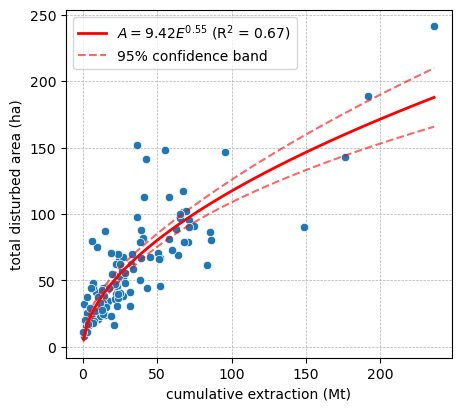

In [8]:
fig = plt.figure(figsize=(4.5, 4), constrained_layout=True)

ax1 = plt.subplot(1, 1, 1)
sns.scatterplot(x=X, y=Y, zorder=3)
ax1.plot(x_sim, y_sim, lw=2.0, color='r', label=f'$A={a:.2f}E^{{{b:.2f}}}$ (R$^{2}$ = {round(r2, 2)})', zorder=5)
ax1.plot(x_sim, y_lo, ls='--', c='r', alpha=0.6, zorder=5)
ax1.plot(x_sim, y_hi, ls='--', c='r', alpha=0.6, zorder=5, label='95% confidence band')
ax1.grid('on', ls='--', lw=0.5)
ax1.legend(loc='best', fontsize=10)
ax1.set(xlabel='cumulative extraction (Mt)', ylabel='total disturbed area (ha)')

plt.show()
fig.savefig(FIGURES / 'Supplementary-Figure-14.jpg', dpi=600, bbox_inches='tight')

A = 9.421 * E^0.548   (n=113, dof=111, residual sd = 22.0 ha)
95% confidence band covers 22% of quarries; 95% prediction band covers 93% of quarries


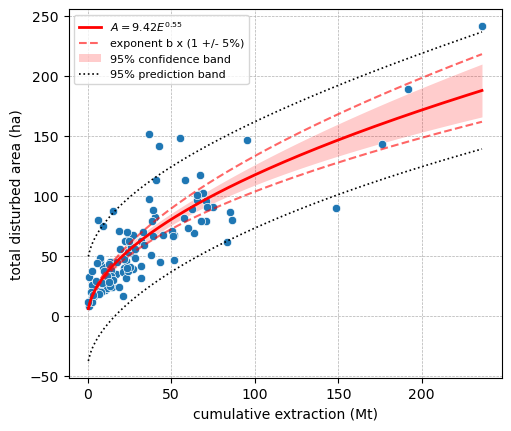

In [ ]:
# === Compare uncertainty bands for the extraction-area power law (Supplementary Figure 14) ===
# The figure above draws its dashed envelope by perturbing the exponent b by +/-5% (illustrative only).
# Notebook 6 (mining-area propagation, predict_interval) instead derives the band from the curve_fit
# parameter covariance. Here we overlay, for comparison:
#   (1) exponent b x (1 +/- 5%)           - the original illustrative dashed lines
#   (2) 95% confidence band of the mean   - parameter covariance only (== notebook 6 predict_interval)
#   (3) 95% prediction band               - parameter covariance + residual scatter (individual quarries)

popt, pcov = curve_fit(func_1, X, Y)
a, b = popt
n = len(X); dof = n - len(popt)
resid = Y - func_1(X, a, b)
s2 = (resid @ resid) / dof                       # residual variance (mean square error)
tval = t.ppf(0.975, dof)

x_line = np.linspace(min(X), max(X), 200)
y_line = func_1(x_line, a, b)

# delta-method gradient of f = a * x**b  w.r.t. (a, b)
df_da = x_line ** b
df_db = a * x_line ** b * np.log(x_line)
var_mean = pcov[0, 0] * df_da**2 + 2 * pcov[0, 1] * df_da * df_db + pcov[1, 1] * df_db**2
se_mean = np.sqrt(var_mean)                       # SE of the fitted mean
se_pred = np.sqrt(s2 + var_mean)                  # SE for a new observation

ci_lo, ci_hi = y_line - tval * se_mean, y_line + tval * se_mean   # 95% confidence band
pi_lo, pi_hi = y_line - tval * se_pred, y_line + tval * se_pred   # 95% prediction band

# empirical coverage: fraction of quarries falling inside each band
g_da = X ** b; g_db = a * X ** b * np.log(X)
v_pts = pcov[0, 0] * g_da**2 + 2 * pcov[0, 1] * g_da * g_db + pcov[1, 1] * g_db**2
ci_cov = np.mean(np.abs(resid) <= tval * np.sqrt(v_pts))
pi_cov = np.mean(np.abs(resid) <= tval * np.sqrt(s2 + v_pts))
print(f'A = {a:.3f} * E^{b:.3f}   (n={n}, dof={dof}, residual sd = {np.sqrt(s2):.1f} ha)')
print(f'95% confidence band covers {ci_cov*100:.0f}% of quarries; '
      f'95% prediction band covers {pi_cov*100:.0f}% of quarries')

fig = plt.figure(figsize=(5, 4.2), constrained_layout=True)
ax = plt.subplot(1, 1, 1)
sns.scatterplot(x=X, y=Y, zorder=3, ax=ax)
ax.plot(x_line, y_line, lw=2.0, color='r', zorder=6, label=f'$A={a:.2f}E^{{{b:.2f}}}$')
# (1) original +/-5% exponent dashed lines
ax.plot(x_line, func_1(x_line, a, b * 1.05), ls='--', c='r', alpha=0.6, zorder=5)
ax.plot(x_line, func_1(x_line, a, b * 0.95), ls='--', c='r', alpha=0.6, zorder=5,
        label='exponent b x (1 +/- 5%)')
# (2) 95% confidence band (parameter covariance) - what notebook 6 propagates
ax.fill_between(x_line, ci_lo, ci_hi, color='red', alpha=0.20, lw=0, zorder=2,
                label='95% confidence band')
# (3) 95% prediction band (+ residual scatter)
ax.plot(x_line, pi_lo, ls=':', c='k', lw=1.2, zorder=4)
ax.plot(x_line, pi_hi, ls=':', c='k', lw=1.2, zorder=4, label='95% prediction band')
ax.grid(True, ls='--', lw=0.5)
ax.legend(loc='upper left', fontsize=8)
ax.set(xlabel='cumulative extraction (Mt)', ylabel='total disturbed area (ha)')
plt.show()
# fig.savefig(FIGURES / 'Supplementary-Figure-14.jpg', dpi=600, bbox_inches='tight')
